In [1]:
import pandas as pd

df = pd.read_csv("../data/processed/cleaned_patient_dataset.csv")

df.head()

,Age,Gender,Height_cm,Weight_kg,BMI,Chronic_Disease,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol_Level,Blood_Sugar_Level,...,Protein_Intake,Carbohydrate_Intake,Fat_Intake,Preferred_Cuisine,Food_Aversions,Recommended_Calories,Recommended_Protein,Recommended_Carbs,Recommended_Fats,Recommended_Meal_Plan
0,56,Other,163,66,24.84,No Disease,175,75,219,124,...,105,179,143,Western,NaN,2150,108,139,145,High-Protein Diet
1,69,Female,171,114,38.99,No Disease,155,72,208,72,...,69,315,75,Mediterranean,NaN,1527,74,266,80,Low-Carb Diet
2,46,Female,172,119,40.22,No Disease,137,101,171,145,...,183,103,148,Western,Sweet,2359,180,145,143,Low-Carb Diet
3,32,Female,197,118,30.41,No Disease,148,91,258,235,...,135,371,120,Western,NaN,2858,137,378,135,Low-Carb Diet
4,60,Female,156,109,44.79,Hypertension,160,109,260,248,...,167,298,48,Indian,Spicy,1937,166,317,56,Low-Carb Diet


scoring system

In [3]:
DIETS = [
    "Balanced Diet",
    "Low-Carb Diet",
    "Low-Fat Diet",
    "High-Protein Diet"
]

helper function

In [4]:
def initialize_scores():

    return {
        "Balanced Diet": 0,
        "Low-Carb Diet": 0,
        "Low-Fat Diet": 0,
        "High-Protein Diet": 0
    }

Cell 4 – Weighted Inference Engine

In [5]:
def weighted_expert_system(row):

    scores = initialize_scores()
    reasons = []

    bmi = row["BMI"]
    disease = row["Chronic_Disease"]
    sugar = row["Blood_Sugar_Level"]
    cholesterol = row["Cholesterol_Level"]
    exercise = row["Exercise_Frequency"]
    steps = row["Daily_Steps"]

    # -------------------------
    # BMI Rules
    # -------------------------

    if bmi < 18.5:
        scores["High-Protein Diet"] += 4
        reasons.append("Underweight → High-Protein +4")

    elif bmi < 25:
        scores["Balanced Diet"] += 3
        reasons.append("Normal BMI → Balanced +3")

    elif bmi < 30:
        scores["Balanced Diet"] += 2
        scores["Low-Carb Diet"] += 1
        reasons.append("Overweight → Balanced +2, Low-Carb +1")

    else:
        scores["Low-Carb Diet"] += 4
        reasons.append("Obese → Low-Carb +4")

    # -------------------------
    # Disease Rules
    # -------------------------

    if disease == "Diabetes":
        scores["Low-Carb Diet"] += 5
        reasons.append("Diabetes → Low-Carb +5")

    elif disease == "Heart Disease":
        scores["Low-Fat Diet"] += 5
        reasons.append("Heart Disease → Low-Fat +5")

    elif disease == "Hypertension":
        scores["Low-Fat Diet"] += 4
        reasons.append("Hypertension → Low-Fat +4")

    # -------------------------
    # Blood Sugar
    # -------------------------

    if sugar >= 180:
        scores["Low-Carb Diet"] += 3
        reasons.append("High Blood Sugar → Low-Carb +3")

    # -------------------------
    # Cholesterol
    # -------------------------

    if cholesterol >= 240:
        scores["Low-Fat Diet"] += 3
        reasons.append("High Cholesterol → Low-Fat +3")

    # -------------------------
    # Lifestyle
    # -------------------------

    if exercise >= 4:
        scores["Balanced Diet"] += 2
        reasons.append("Regular Exercise → Balanced +2")

    if steps >= 10000:
        scores["Balanced Diet"] += 1
        reasons.append("Active Lifestyle → Balanced +1")

    recommendation = max(scores, key=scores.get)

    return pd.Series([
        recommendation,
        scores,
        reasons
    ])

Cell 5 – Apply the Weighted System

In [6]:
df[
    [
        "Weighted_Meal_Plan",
        "Scores",
        "Reasons"
    ]
] = df.apply(
    weighted_expert_system,
    axis=1
)

Cell 6 – Check Results

In [7]:
df[
    [
        "BMI",
        "Chronic_Disease",
        "Weighted_Meal_Plan",
        "Scores",
        "Reasons"
    ]
].head(10)

,BMI,Chronic_Disease,Weighted_Meal_Plan,Scores,Reasons
0,24.84,No Disease,Balanced Diet,"{'Balanced Diet': 6, 'Low-Carb Diet': 0, 'Low-...","[Normal BMI → Balanced +3, Regular Exercise → ..."
1,38.99,No Disease,Low-Carb Diet,"{'Balanced Diet': 1, 'Low-Carb Diet': 4, 'Low-...","[Obese → Low-Carb +4, Active Lifestyle → Balan..."
2,40.22,No Disease,Low-Carb Diet,"{'Balanced Diet': 0, 'Low-Carb Diet': 4, 'Low-...",[Obese → Low-Carb +4]
3,30.41,No Disease,Low-Carb Diet,"{'Balanced Diet': 2, 'Low-Carb Diet': 7, 'Low-...","[Obese → Low-Carb +4, High Blood Sugar → Low-C..."
4,44.79,Hypertension,Low-Carb Diet,"{'Balanced Diet': 0, 'Low-Carb Diet': 7, 'Low-...","[Obese → Low-Carb +4, Hypertension → Low-Fat +..."
5,27.71,Diabetes,Low-Carb Diet,"{'Balanced Diet': 2, 'Low-Carb Diet': 9, 'Low-...","[Overweight → Balanced +2, Low-Carb +1, Diabet..."
6,15.40,Hypertension,Low-Fat Diet,"{'Balanced Diet': 0, 'Low-Carb Diet': 0, 'Low-...","[Underweight → High-Protein +4, Hypertension →..."
7,31.71,Hypertension,Low-Carb Diet,"{'Balanced Diet': 0, 'Low-Carb Diet': 7, 'Low-...","[Obese → Low-Carb +4, Hypertension → Low-Fat +..."
8,44.20,Heart Disease,Low-Fat Diet,"{'Balanced Diet': 0, 'Low-Carb Diet': 4, 'Low-...","[Obese → Low-Carb +4, Heart Disease → Low-Fat ..."
9,39.45,Heart Disease,Low-Carb Diet,"{'Balanced Diet': 3, 'Low-Carb Diet': 7, 'Low-...","[Obese → Low-Carb +4, Heart Disease → Low-Fat ..."


Cell 7 – Distribution

In [8]:
print(df["Weighted_Meal_Plan"].value_counts())

Weighted_Meal_Plan
Low-Carb Diet        2440
Balanced Diet        1285
Low-Fat Diet          991
High-Protein Diet     284
Name: count, dtype: int64


Cell 8 – Visualization

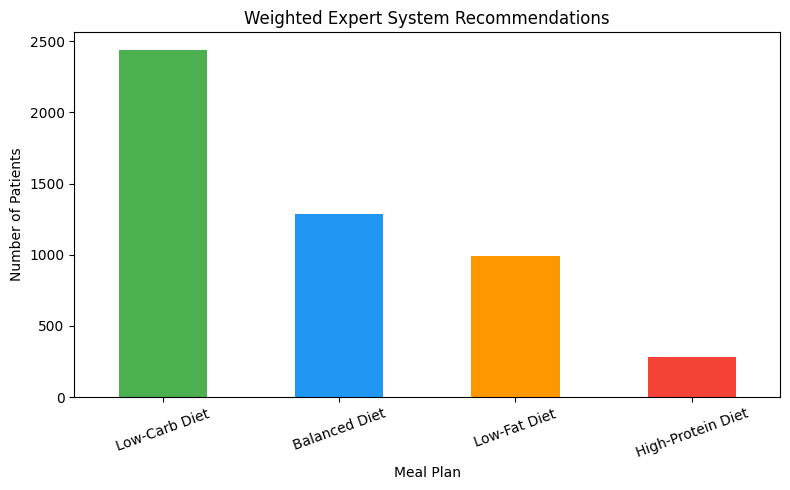

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

df["Weighted_Meal_Plan"].value_counts().plot(
    kind="bar",
    color=["#4CAF50", "#2196F3", "#FF9800", "#F44336"]
)

plt.title("Weighted Expert System Recommendations")
plt.xlabel("Meal Plan")
plt.ylabel("Number of Patients")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig("../reports/figures/weighted_expert_distribution.png")

plt.show()